### Импорты

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import umap

from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.model_selection import GridSearchCV, GroupKFold

import solution_utils as su

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 100, "display.width", 200)

SEED = 42
DATA = os.environ.get("HW1_TRAIN", "./hw1_train.jsonl")
K_FINE = 30                  # на сколько мелких кластеров режем данные для просмотра (с запасом)

### Загрузка данных

In [2]:
dialogs = su.read_dialogs(DATA)
frame = su.to_frame(dialogs)
print("диалогов:", len(frame))
frame[["dialog_id", "first_user", "first_asst"]].head(3)

Обработано 1000 диалогов...
Обработано 2000 диалогов...
Обработано 3000 диалогов...
Обработано 4000 диалогов...
Обработано 5000 диалогов...
Обработано 6000 диалогов...
Обработано 7000 диалогов...
Обработано 8000 диалогов...
Обработано 9000 диалогов...
Обработано 10000 диалогов...
диалогов: 10000


,dialog_id,first_user,first_asst
0,d094012177e,it s like but ? is undefin can you tell which modulus we can possibl use in this concept and int...,introduc scientif term from astrophys or ani other scientif disciplin to the given equat ? may n...
1,d306fbe61fe,can you help me train a small languag model that can answer question i don t want to use a pretr...,creat a small languag model from scratch is a signific undertak as it involv understand deep lea...
2,dd6905952c7,ask question about a fiction voic actor i made and base on the answer describ him,how did this fiction voic actor get into the industri ? what is his most icon role to date ? whi...


### Разбиение

In [3]:
train_idx, test_idx = next(GroupKFold(n_splits=5).split(frame, groups=frame.group))
train = frame.iloc[train_idx].reset_index(drop=True)
test = frame.iloc[test_idx].reset_index(drop=True)
print("train:", len(train), " test:", len(test))

train: 8000  test: 2000


### TF-IDF по трём текстовым колонкам диалога (first_user, rest_user, first_asst), сжатие с помощью TruncatedSVD, Нормировка

In [4]:
lsa = su.topic_lsa(100, SEED)
Z_train = lsa.fit_transform(train)
Z_test = lsa.transform(test)
print("форма:", Z_train.shape,
    "| доля дисперсии, объяснённая 100 компонентами: \
    %.2f" % lsa[1].explained_variance_ratio_.sum())

форма: (8000, 100) | доля дисперсии, объяснённая 100 компонентами:     0.09


### Перебираем количество кластеров

In [5]:
K_RANGE = list(range(4, 250, 10))                    # какие k пробуем
rng_k = np.random.default_rng(SEED)
sub_k = rng_k.choice(len(Z_train), size=min(3000, len(Z_train)), replace=False)  # силуэт — на подвыборке

rows = []
for k in K_RANGE:
    fit_a = KMeans(k, n_init=3, random_state=SEED).fit(Z_train)
    rows.append({"k": k,
                 "инерция": fit_a.inertia_,
                 "силуэт": silhouette_score(Z_train[sub_k], fit_a.labels_[sub_k])})

k_table = pd.DataFrame(rows).set_index("k")

### Графки силуэта и инерции от количества кластеров

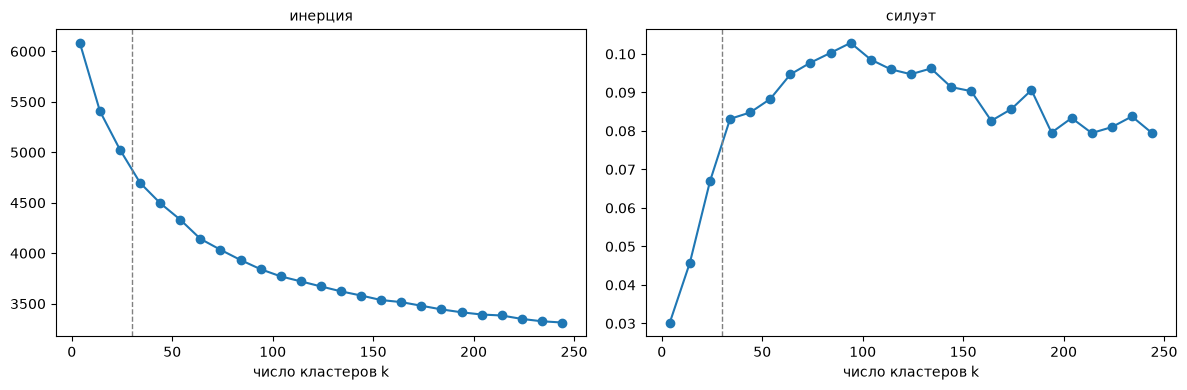

,инерция,силуэт
k,,
4,6084.165,0.030
14,5407.799,0.046
24,5025.093,0.067
34,4697.109,0.083
44,4496.242,0.085
54,4332.248,0.088
64,4142.723,0.095
74,4034.401,0.098
84,3932.932,0.100


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["инерция", "силуэт"]):
    ax.plot(k_table.index, k_table[col], "o-")
    ax.axvline(K_FINE, color="gray", ls="--", lw=1)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("число кластеров k")
plt.tight_layout(); plt.show()

su.show_table(k_table.round(3))

### Вывод диалогов кластеров для ручной разметки

In [7]:
rng = np.random.default_rng(SEED)
km = KMeans(K_FINE, n_init=10, random_state=SEED).fit(Z_train)
train_cluster = km.labels_
test_cluster  = km.predict(Z_test)

N_SHOW = 6
X_train = lsa[0].transform(train)       # TF-IDF до SVD: из него берём слова
terms = np.array([t.split("__", 1)[1] for t in lsa[0].get_feature_names_out()])
short = lambda text, n: " ".join(str(text).split())[:n]

for c in np.argsort(-np.bincount(train_cluster, minlength=K_FINE)):
    idx = np.where(train_cluster == c)[0]
    mean_tfidf = np.asarray(X_train[idx].mean(axis=0)).ravel()
    top = list(dict.fromkeys(terms[mean_tfidf.argsort()[::-1][:30]]))[:10]
    order = idx[np.argsort(((Z_train[idx] - km.cluster_centers_[c]) ** 2).sum(axis=1))]
    shown = list(order[:3]) + list(rng.choice(order[3:], size=min(N_SHOW - 3, max(len(order) - 3, 0)), replace=False))
    print(f"\n=== кластер {c}: {len(idx)} диалогов ({len(idx) / len(train):.1%}) ===")
    print("слова:", ", ".join(top))
    for i in shown:
        print("   •", short(train.raw_first.iloc[i], 160))


=== кластер 29: 581 диалогов (7.3%) ===
слова: the, to, and, a, of, be, it, that, in, is
   • You are able to be creative now and give result of puzzle This puzzle cantina The @superformxyz team will kick off their $100,000 competition-style CTF very soo
   • When considering fining agents or flocculants that can be burnt off, leaving the least amount of residual carbon or substances, the selection narrows down to th
   • the critique given in what follows of hell under that description is not aimed at Christian doctrine but at a particular speculative reading of it. Second, that
   • proofread it to be more academic: In addition to the aforementioned NRV framework, there is another model also predicts different discrimination performances as
   • try minify IT ANY FURTHER: ♜ ⬛ ♞ ⬜ ♝ ⬛ ♛ ⬜ ♚ ⬛ ♝ ⬜ ♞ ⬛ ♜ ⬜ ♟ ⬜ ♟ ⬛ ♟ ⬜ ♟ ⬛ ♟ ⬜ ♟ ⬛ ♟ ⬜ ♟ ⬛ ⬛⬜⬛⬜⬛⬜⬛⬜ ⬜⬛⬜⬛⬜⬛⬜⬛ ⬛⬜⬛⬜⬛⬜⬛⬜ ⬜⬛⬜⬛⬜⬛⬜⬛ ♙ ⬜ ♙ ⬛ ♙ ⬜ ♙ ⬛ ♙ ⬜ ♙ ⬛ ♙ ⬜ ♙ ⬛ ♖
   • Read the Case Study: The Vigilance Project. from Answer the following quest

### Ручная разметка

In [8]:
CLUSTER_TO_TOPIC = {
    0: "программирование, код и техническая реализация",
    1: "программирование, код и техническая реализация",
    2: "справочные вопросы, объяснения, инструкции и списки",
    3: "академические, деловые и аналитические тексты",
    4: "справочные вопросы, объяснения, инструкции и списки",
    5: "математика, физика, инженерия и алгоритмы",
    6: "академические, деловые и аналитические тексты",
    7: "справочные вопросы, объяснения, инструкции и списки",
    8: "академические, деловые и аналитические тексты",
    9: "справочные вопросы, объяснения, инструкции и списки",
    10: "творческое письмо, истории, фанфики и генерация контента",
    11: "творческое письмо, истории, фанфики и генерация контента",
    12: "перевод",
    13: "программирование, код и техническая реализация",
    14: "смешанные и ролевые запросы",
    15: "справочные вопросы, объяснения, инструкции и списки",
    16: "справочные вопросы, объяснения, инструкции и списки",
    17: "творческое письмо, истории, фанфики и генерация контента",
    18: "академические, деловые и аналитические тексты",
    19: "приветствия и начало диалога",
    20: "справочные вопросы, объяснения, инструкции и списки",
    21: "творческое письмо, истории, фанфики и генерация контента",
    22: "программирование, код и техническая реализация",
    23: "программирование, код и техническая реализация",
    24: "академические, деловые и аналитические тексты",
    25: "просьбы о помощи и выполнении задач",
    26: "математика, физика, инженерия и алгоритмы",
    27: "справочные вопросы, объяснения, инструкции и списки",
    28: "справочные вопросы, объяснения, инструкции и списки",
    29: "академические, деловые и аналитические тексты",
}

TOPIC_DESCRIPTIONS = {
    "программирование, код и техническая реализация": "запросы на написание, исправление и объяснение кода, работа с библиотеками, отладка и технические задачи",
    "справочные вопросы, объяснения, инструкции и списки": "вопросы на получение фактов, определений, объяснений, пошаговых инструкций и списков",
    "академические, деловые и аналитические тексты": "запросы на написание, переписывание, анализ и редактирование академических, деловых и аналитических материалов",
    "математика, физика, инженерия и алгоритмы": "решение задач по математике, физике, инженерии, статистике и алгоритмам",
    "творческое письмо, истории, фанфики и генерация контента": "просьбы написать истории, сценарии, фанфики, креативные тексты и другой художественный контент",
    "перевод": "запросы на перевод текста с одного языка на другой и языковые вставки",
    "смешанные и ролевые запросы": "нестандартные, смешанные или ролевые задания, где нужно действовать от лица персонажа или эксперта",
    "приветствия и начало диалога": "короткие приветствия, проверка связи и вступительные реплики",
    "просьбы о помощи и выполнении задач": "просьбы помочь с задачей, дать совет, выполнить действие или предоставить информацию",
}

topic_of_cluster = {c: CLUSTER_TO_TOPIC.get(c, f"topic_{c:02d}") for c in range(K_FINE)}
y_train = pd.Series(train_cluster).map(topic_of_cluster).to_numpy()
y_test = pd.Series(test_cluster).map(topic_of_cluster).to_numpy()
K = len(set(y_train))
print("итоговое число тем:", K)
su.show_table(pd.Series(y_train).value_counts(normalize=True).round(3).to_frame("доля"))

итоговое число тем: 9


,доля
"академические, деловые и аналитические тексты",0.289
"справочные вопросы, объяснения, инструкции и списки",0.222
"программирование, код и техническая реализация",0.200
"творческое письмо, истории, фанфики и генерация контента",0.131
"математика, физика, инженерия и алгоритмы",0.064
смешанные и ролевые запросы,0.041
просьбы о помощи и выполнении задач,0.029
приветствия и начало диалога,0.013
перевод,0.010


### Umap

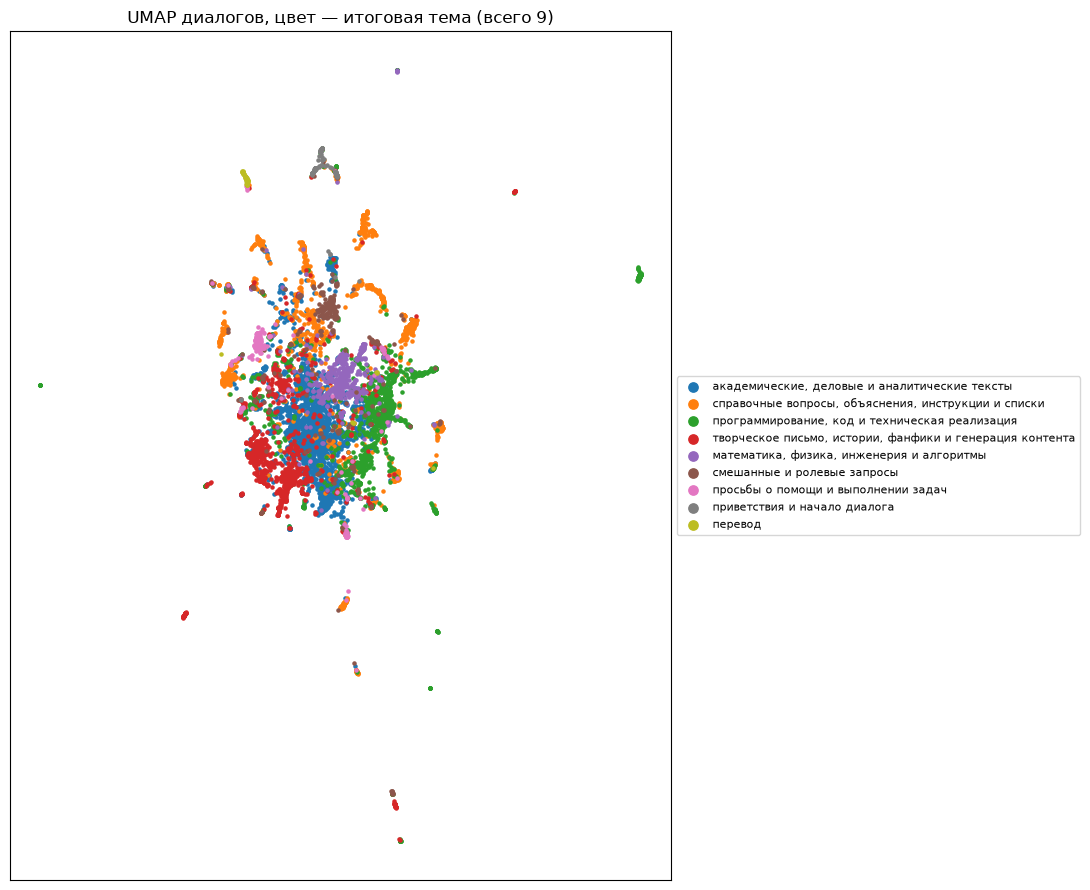

In [9]:

reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="cosine", random_state=SEED)
emb = reducer.fit_transform(Z_train)                # весь Z_train: N × 2

y_arr = np.asarray(y_train)                         # N
assert len(emb) == len(y_arr), (len(emb), len(y_arr))

fig, ax = plt.subplots(figsize=(11, 9))
for name in pd.Series(y_arr).value_counts().index:
    m = y_arr == name
    ax.scatter(emb[m, 0], emb[m, 1], s=5, label=name)

ax.legend(markerscale=3, fontsize=8, loc="center left", bbox_to_anchor=(1, 0.5))
ax.set_title(f"UMAP диалогов, цвет — итоговая тема (всего {K})")
ax.set_xticks([])
ax.set_yticks([])
plt.tight_layout()
plt.show()

### По три диалога на тему и доля диалогов этой темы в данных

In [10]:
for name in pd.Series(y_train).value_counts().index:
    idx = np.where(y_train == name)[0]
    centre = Z_train[idx].mean(axis=0)
    nearest = idx[np.argsort(((Z_train[idx] - centre) ** 2).sum(axis=1))[:3]]
    examples = " | ".join(short(train.raw_first.iloc[i], 80) for i in nearest)
    print(f"{name} ({len(idx)/len(train):.1%}, {len(idx)}): {examples}")

академические, деловые и аналитические тексты (28.9%, 2312): Please explain like I am a high school student: The Dawn of Causal Factor Invest | Using this article is deregulation good in the air travel industry? In 2009, des | I have to write a news based on this set of information. First set of informatio
справочные вопросы, объяснения, инструкции и списки (22.2%, 1776): what genre is dm galaxy bad motives? | what triggers a "app is not responding" message? What goes on inside the network | how are mirrors made nowadays? what is the technique for the highest quality mir
программирование, код и техническая реализация (20.0%, 1598): Read the following Part I of the project I started implementing. I’ll provide yo | I have this Arduino code; this code read the values of a 10K potentiometer which | Component CImage::bfsComponent(int pr, int pc, int mylabel) / Arrays to help pro
творческое письмо, истории, фанфики и генерация контента (13.1%, 1051): At this school the girls all play rugby r

### Обучение моделей и метрики

In [11]:
MODELS = su.topic_models(SEED)
inner_cv = GroupKFold(n_splits=3)

fitted, preds, rows = {}, {}, []
for name, (pipe, grid) in MODELS.items():
    if grid:
        search = GridSearchCV(pipe, grid, cv=inner_cv, scoring="f1_macro", n_jobs=-1)
        search.fit(train, y_train, groups=train.group)
        model, cv_f1, params = search.best_estimator_, search.best_score_, search.best_params_
    else:
        model, cv_f1, params = clone(pipe).fit(train, y_train), np.nan, {}
    fitted[name], preds[name] = model, model.predict(test)
    rows.append({"model": name, "cv_macro_f1": cv_f1, **su.partition_scores(y_test, preds[name]), "params": params})

topic_table = pd.DataFrame(rows)
COLS = ["model", "ARI", "NMI", "однородность", "полнота", "V-мера", "чистота"]
su.show_table(topic_table[COLS].round(3))

,model,ARI,NMI,однородность,полнота,V-мера,чистота
0,dummy_one_topic,0.000,0.000,0.000,1.000,0.000,0.309
1,nb,0.387,0.390,0.379,0.402,0.390,0.684
2,logreg,0.676,0.669,0.672,0.667,0.669,0.858
3,linear_svm,0.657,0.652,0.656,0.648,0.652,0.849
4,own_lsa_rbf_svm,0.781,0.759,0.760,0.758,0.759,0.906


### Сохранение моделей

In [12]:
OUT = os.path.join(su.ARTIFACTS, "topic_models")
os.makedirs(OUT, exist_ok=True)

for name, model in fitted.items():
    path = os.path.join(OUT, f"topic_{name}.joblib")
    joblib.dump(model, path)
    print("saved:", path)

saved: /home/salexq/ml_dafe_mipt/homeworks/hw1/grisha/rep_hw/hw1/artifacts/topic_models/topic_dummy_one_topic.joblib
saved: /home/salexq/ml_dafe_mipt/homeworks/hw1/grisha/rep_hw/hw1/artifacts/topic_models/topic_nb.joblib
saved: /home/salexq/ml_dafe_mipt/homeworks/hw1/grisha/rep_hw/hw1/artifacts/topic_models/topic_logreg.joblib
saved: /home/salexq/ml_dafe_mipt/homeworks/hw1/grisha/rep_hw/hw1/artifacts/topic_models/topic_linear_svm.joblib
saved: /home/salexq/ml_dafe_mipt/homeworks/hw1/grisha/rep_hw/hw1/artifacts/topic_models/topic_own_lsa_rbf_svm.joblib
